# Imports, Dados e Hold-Out

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from scipy.stats import norm
from scipy.optimize import minimize_scalar
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor  
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform
from xgboost import XGBRegressor
from sklearn.svm import SVR


def rmse_clipped(y_true, y_pred):
    """
    RMSE after clipping predictions to [0, 5].

    Matches the competition metric, where predictions are limited to the
    valid star range before scoring.

    Parameters
    ----------
    y_true : array-like
        Observed star ratings.
    y_pred : array-like
        Raw model predictions (may fall outside [0, 5]).

    Returns
    -------
    float
        Root mean squared error between y_true and the clipped predictions.
    """
    return np.sqrt(mean_squared_error(y_true, np.clip(y_pred, 0, 5)))

scorer = make_scorer(rmse_clipped, greater_is_better=False)


evaluation_specs = []

def evaluate(model, X, y):
    """
    Returns (mean CV RMSE, SE, variables used).
    Also stores the estimator and feature names for the final hold-out evaluation.
    """
    s = -cross_val_score(model, X, y, cv=cv, scoring=scorer)
    cols = list(X.columns)
    if hasattr(model, "named_steps") and "sequentialfeatureselector" in model.named_steps:
        fitted = clone(model).fit(X, y)
        cols = list(X.columns[fitted.named_steps["sequentialfeatureselector"].get_support()])

    evaluation_specs.append((clone(model), X.copy()))
    return round(s.mean(), 4), round(s.std() / np.sqrt(len(s)), 4), ", ".join(cols)


def selected_linear():
    """
    Build a linear regression pipeline with forward variable selection.

    Steps: standardize -> forward selection -> OLS on the chosen variables.
    Selection uses an inner 5-fold CV on the training fold, and stops adding
    variables when the CV RMSE improves by less than `tol` (0.002). Lower
    `tol` keeps more variables.

    Returns a fresh, unfitted pipeline each call so evaluate() can clone it
    per fold. Because selection sits inside the pipeline, it is redone on
    every training fold and the CV RMSE is not optimistic.

    Caveat: forward selection is greedy and can stop early when variables
    only help in combination.

    Returns
    -------
    sklearn.pipeline.Pipeline
    """
    return make_pipeline(
        StandardScaler(),
        SequentialFeatureSelector(
            LinearRegression(),
            n_features_to_select="auto", tol=0.002,
            direction="forward",
            scoring="neg_root_mean_squared_error", cv=5),
        LinearRegression())


def oof_residuals(model, Xm, y):
    """
    Out-of-fold predictions and residuals for diagnostic plots.

    Each row is predicted by a model that did not see it, using a single
    stratified 5-fold split (cross_val_predict needs every row predicted
    exactly once, so it cannot use the repeated `cv` list). Uses the globals
    `SEED` and `strata` (genre + stars label) for reproducible, stratified folds.

    Parameters
    ----------
    model : sklearn estimator or Pipeline
        Unfitted model to diagnose.
    Xm : pd.DataFrame
        Feature matrix to fit on (pass the one you want to diagnose).
    y : pd.Series
        Target (stars).

    Returns
    -------
    pred : np.ndarray
        Out-of-fold predictions, clipped to [0, 5].
    resid : pd.Series
        y - pred. Positive values mean the model underpredicted.
    """
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    pred = np.clip(cross_val_predict(model, Xm, y, cv=skf.split(Xm, strata)), 0, 5)
    return pred, y - pred

SEED = 2026
DATA = Path("Data")
DATA.mkdir(exist_ok=True)

df = pd.read_csv(DATA / "train.csv")

strata = df["genre"] + "_" + df["stars"].round().clip(lower=1).astype(int).astype(str)
print(strata.value_counts().min(), "rows in the smallest stratum")

62 rows in the smallest stratum


O menor estrato (gênero, estrelas) tem 62 linhas, então podemos tranquilamente dividir o conjunto de dados entre treino e teste (hold-out). Por motivos empíricos, iremos segurar 20% das linhas.

In [2]:
pure_train, hold_out = train_test_split(
    df, test_size=0.2, stratify=strata, random_state=SEED
)
pure_train = pure_train.reset_index(drop=True)
hold_out = hold_out.reset_index(drop=True)

pure_train.to_csv(DATA / "pure_train.csv", index=False)
hold_out.to_csv(DATA / "hold_out.csv", index=False)
print(pure_train.shape, hold_out.shape)

(3200, 12) (800, 12)


In [3]:
df = pure_train.copy()

X = pd.get_dummies(df.drop(columns=["pair_id", "stars"]), columns=["genre"], drop_first=True) #one-hot encoding
X = X.drop(columns=["share_drama"])
y = df["stars"]

strata = df["genre"] + "_" + df["stars"].round().clip(lower=1).astype(int).astype(str)
cv = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X, strata))

In [ ]:
evaluation_specs = []
results = {}

results["Constante"] = evaluate(DummyRegressor(strategy="mean"), X, y)
results["Linear"] = evaluate(make_pipeline(StandardScaler(), LinearRegression()), X, y)
pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_act..."
Linear,0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_act..."


# Análise Exploratória

In [ ]:
df = pure_train.copy()
rng = np.random.default_rng(0)

# Jittered stars: adicionamos pequenos distúrbios no valor de estrelas para a nuvem de pontos ficar mais visível
y_jit = (df["stars"] + rng.uniform(-0.15, 0.15, len(df))).clip(0, 5)

# share_match: incluímos uma variável nova
df["share_match"] = df.apply(lambda r: r[f"share_{r['genre']}"], axis=1)

def fix_axes(ax):
    """Fix axes to make the plot consistent."""
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=-0.15, top=5.15)

feats = ["user_avg_stars", "user_n_ratings", "age",
         "share_action", "share_comedy", "share_drama",
         "movie_avg_stars", "movie_n_ratings", "release_year",
         "share_match"]

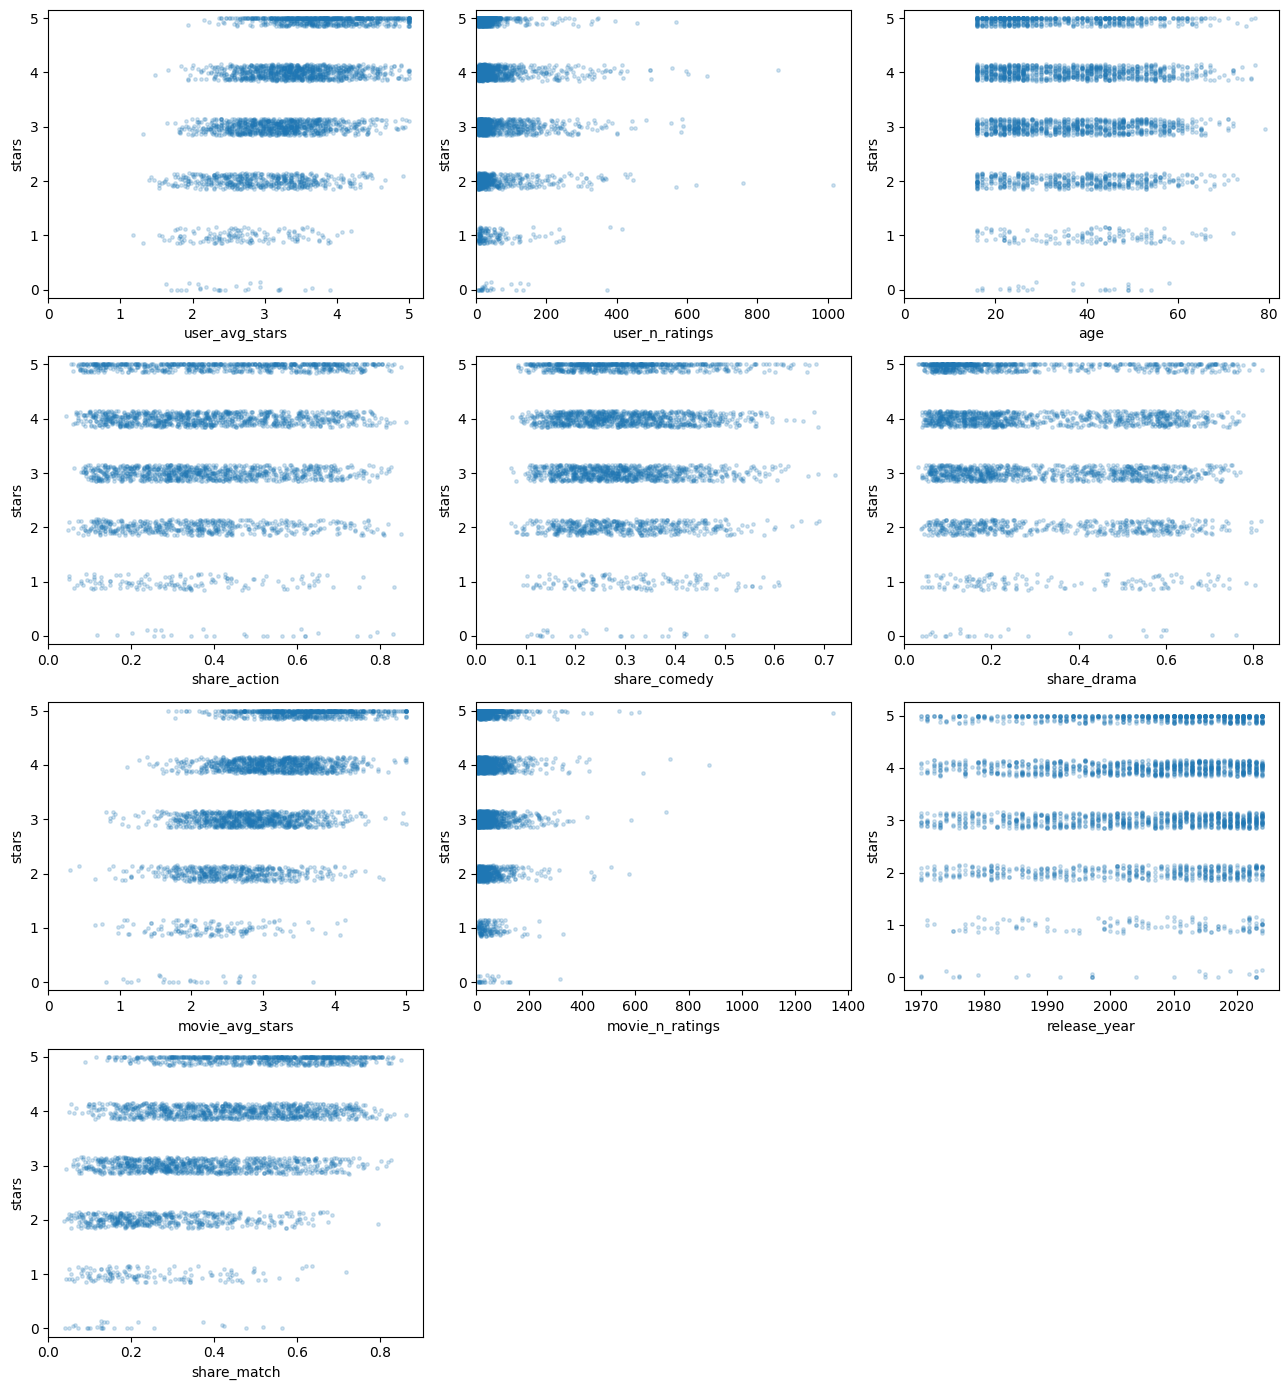

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(13, 14))
for ax, f in zip(axes.ravel(), feats):
    ax.scatter(df[f], y_jit, alpha=0.2, s=6)
    ax.set_xlabel(f); ax.set_ylabel("stars")
    if f != "release_year":
        fix_axes(ax)
for ax in axes.ravel()[len(feats):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

- Como esperado, usuários que tem uma maior média de estrelas costumam dar estrelas maiores; o mesmo acontece com filmes que tem avaliação média maior;
- Vemos uma concentração de usuários com poucas avaliações. Há uma impressão de que usuários com mais avaliações dão mais estrelas 3, mas isso pode ser apenas pela própria distribuição de estrelas; o mesmo acontece com filmes mais avaliados;
- Em primeiro momento, usuários mais velhos parecem não gostar de dar estrelas baixas. Apesar disso, é inconclusivo: temos poucas estrelas baixas e poucos usuários mais velhos. As outras faixas estão bem distribuídas;
- Há uma desconcentração de pontos para usuários com alta proporção de filmes de ação assistidos e estrelas baixas, especialmente a partir de 2 estrelas; para a proporção de filmes de comédia, parece ter-se uma uniformidade maior ao longo de uma mesma estrela; o mesmo acontece com os filmes de drama;
- O ano do filme parece não ter relação com o número de estrelas dado;
- O último gráfico mostra no eixo x a porcentagem do gênero assistido do usuário que é o gênero do filme. Ou seja, o quanto o usuário assistiu daquele gênero tem relação positiva com o número de estrelas.

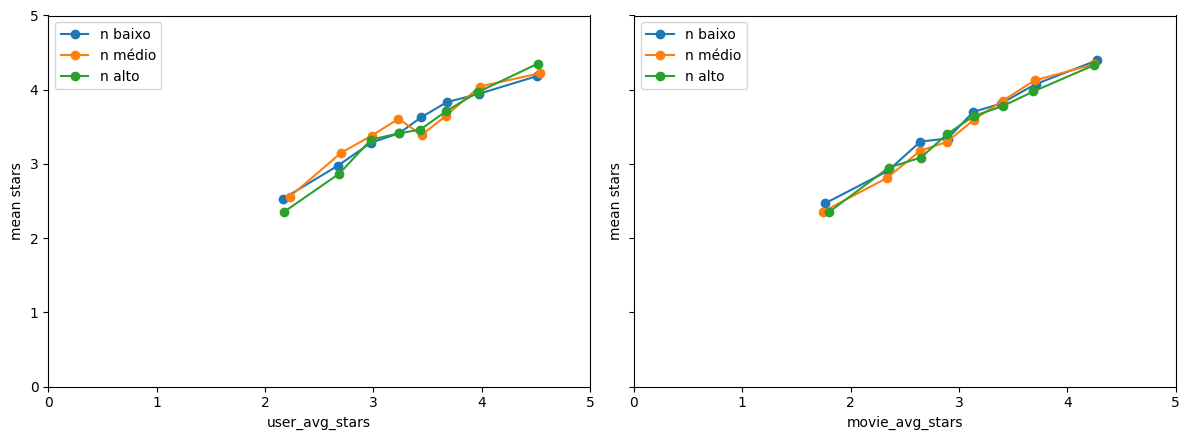

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (avg, n) in zip(axes, [("user_avg_stars", "user_n_ratings"),
                               ("movie_avg_stars", "movie_n_ratings")]):
    d = df.copy()
    d["n_grp"] = pd.qcut(d[n], 3, labels=["n baixo", "n médio", "n alto"])
    d["bin"] = pd.qcut(d[avg], 8, duplicates="drop")
    for g, sub in d.groupby("n_grp", observed=True):
        m = sub.groupby("bin", observed=True).agg(x=(avg, "mean"), y=("stars", "mean"))
        ax.plot(m["x"], m["y"], "o-", label=g)
    ax.set_xlabel(avg); ax.set_ylabel("mean stars"); ax.legend()
    ax.set_ylim(bottom=0, top = 5)
    ax.set_xlim(left= 0, right = 5)
plt.tight_layout(); plt.show()

Os gráficos acima mostram linhas com baixo, médio, e alto número de avaliações (pelo usuário e para o filme), em relação ao número médio de estrelas. Como podemos ver, a confiabilidade da avaliação parece não ter relação com o número de avaliações, o que é surpreendente.

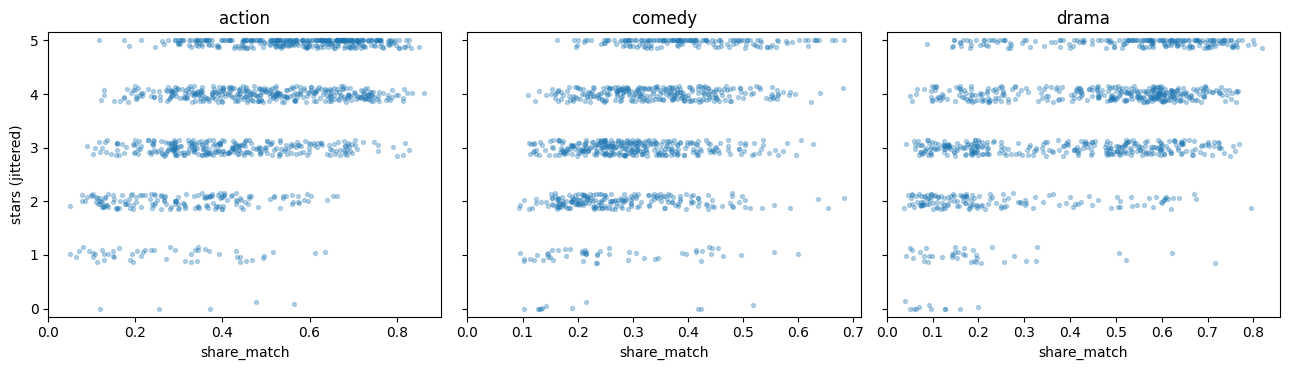

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, g in zip(axes, ["action", "comedy", "drama"]):
    d = df[df["genre"] == g]
    yj = (d["stars"] + rng.uniform(-0.15, 0.15, len(d))).clip(0, 5)
    ax.scatter(d["share_match"], yj, alpha=0.3, s=8)
    ax.set_title(g); ax.set_xlabel("share_match")
    fix_axes(ax)
axes[0].set_ylabel("stars (jittered)")
plt.tight_layout(); plt.show()

Como visto anteriormente, especialmente para o gênero ação, usuários dão mais estrelas para gêneros que assistem mais.

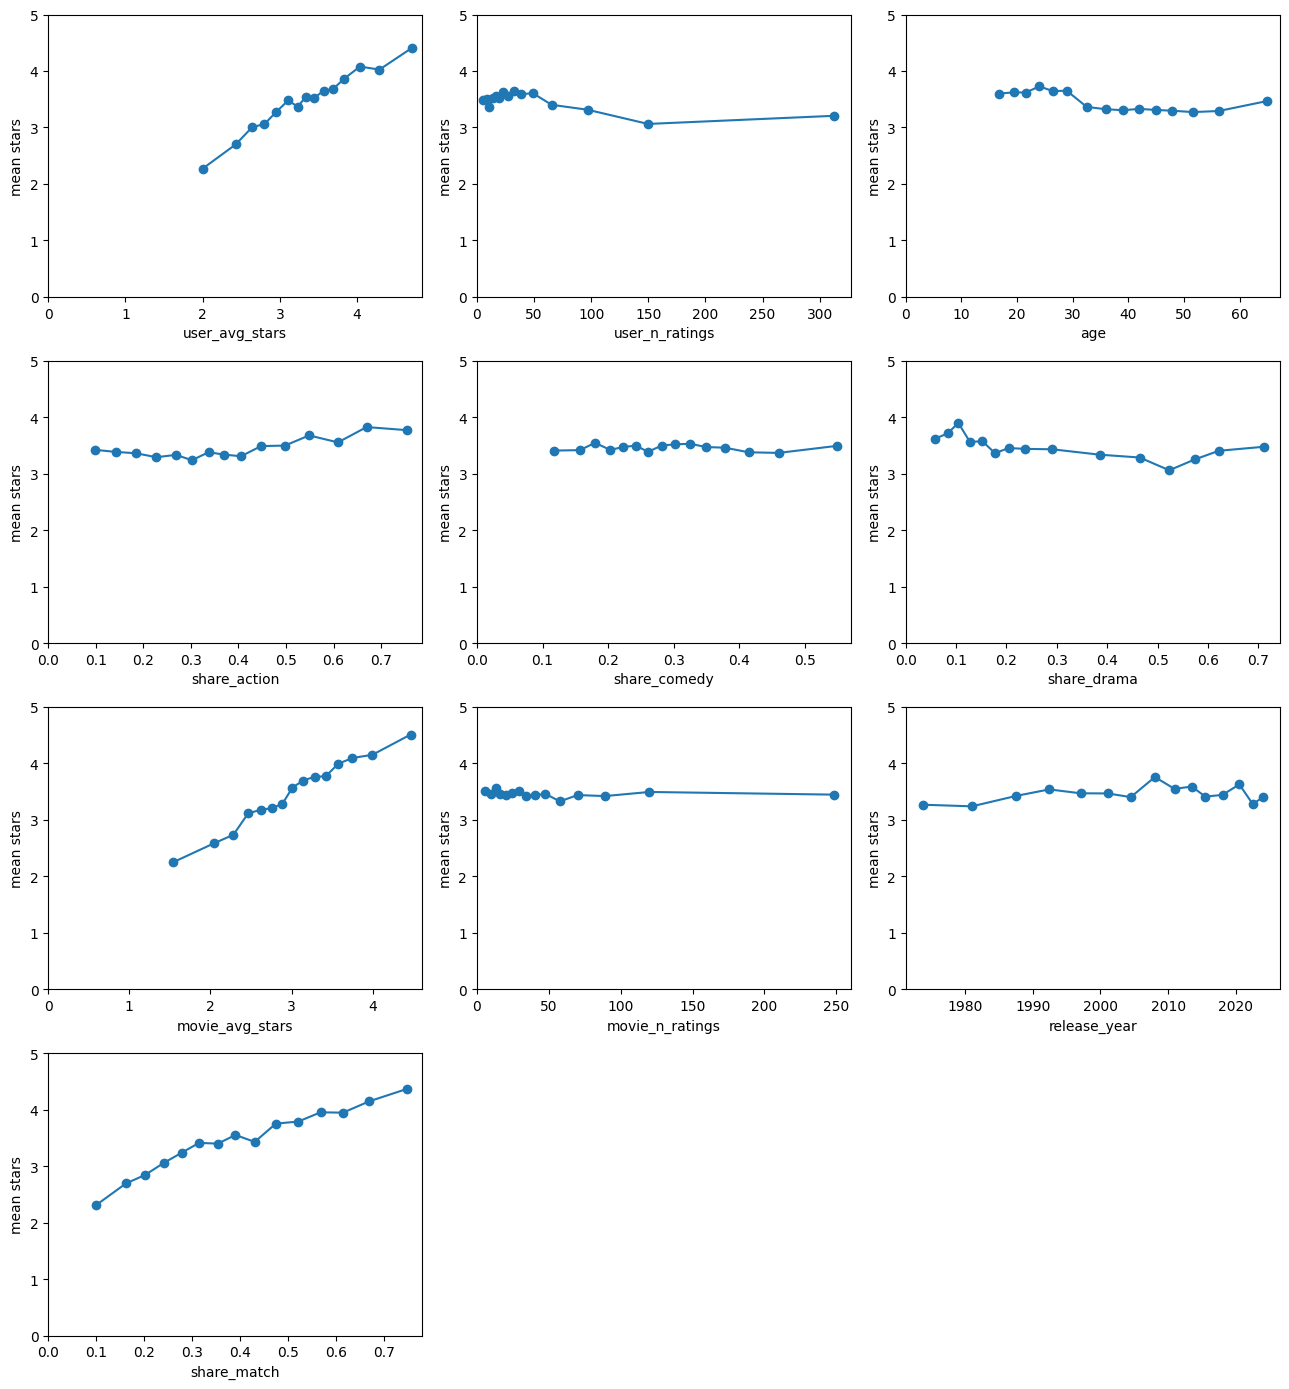

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(13, 14))
for ax, f in zip(axes.ravel(), feats):
    b = pd.qcut(df[f], 15, duplicates="drop")
    m = df.groupby(b, observed=True).agg(x=(f, "mean"), y=("stars", "mean"))
    ax.plot(m["x"], m["y"], "o-")
    ax.set_xlabel(f); ax.set_ylabel("mean stars")
    if f != "release_year":
        fix_axes(ax)
    ax.set_ylim(0, 5)          
for ax in axes.ravel()[len(feats):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

O painel acima condensa parte das informações que obtivemos acima, sem a bagunça da nuvem de pontos. Dividimos as variáveis em 15 pontos e calculamos a média. Note que as 3 variáveis mais importantes analisadas são: as médias de avaliação e a proporção de filmes assistidos do mesmo gênero.

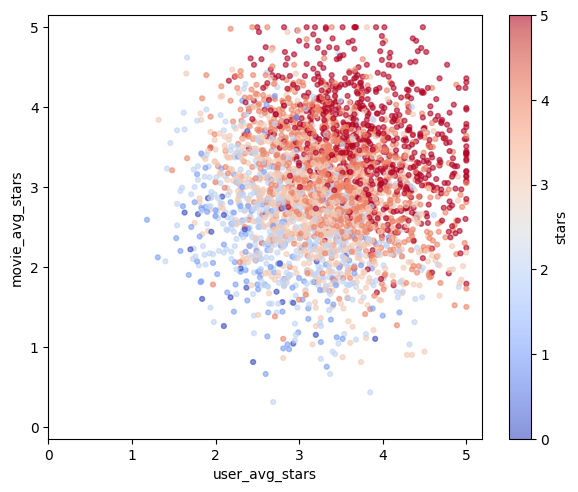

In [ ]:
plt.figure(figsize=(7, 5.5))
sc = plt.scatter(df["user_avg_stars"], df["movie_avg_stars"],
                 c=df["stars"], cmap="coolwarm", alpha=0.6, s=12)
plt.colorbar(sc, label="stars")
plt.xlabel("user_avg_stars"); plt.ylabel("movie_avg_stars")
fix_axes(plt.gca())
plt.show()

Parece que o efeito das variáveis de média é aditivo. Ainda assim, há uma mistura de cores no meio e nos cantos. Uma das hipóteses é que a outra variável importante, `share_match`, explica boa parte dessa confusão.

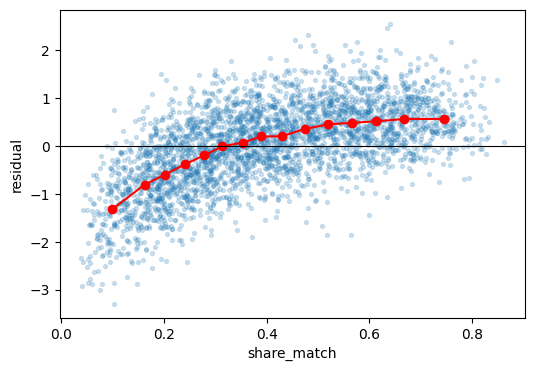

In [ ]:
from sklearn.linear_model import LinearRegression

X_res = df[["user_avg_stars", "movie_avg_stars"]]
resid = df["stars"] - LinearRegression().fit(X_res, df["stars"]).predict(X_res)

plt.figure(figsize=(6, 4))
plt.scatter(df["share_match"], resid, alpha=0.2, s=8)
b = pd.qcut(df["share_match"], 15, duplicates="drop")
m = pd.DataFrame({"x": df["share_match"], "r": resid}).groupby(b, observed=True).mean()
plt.plot(m["x"], m["r"], "r-o")
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("share_match"); plt.ylabel("residual")
plt.show()

Acima temos os resíduos de um modelo linear usando as médias, plotado contra a variável. Note que há um efeito forte. Na verdade, há várias interpretações importantes que surgem desse gráfico:

- Usuários que assistem pouco do gênero avaliam baixo; a partir de um certo momento, a adição de mais porcentagem de gênero não aumenta tanto a nota dada;
- A linha plotada dos resíduos cruza o eixo x em `share_match` próxima de 0.33 $\left(\frac{1}{3}\right)$, que é o caso em que não há preferência de gênero;
- Ainda há uma grande dispersão nos resíduos.

## Modelos iniciais

In [ ]:
X2 = X.copy()
X2["share_match"] = df.apply(lambda r: r[f"share_{r['genre']}"], axis=1)
X3 = X2.copy()
X3["share_match"] = np.log(X3["share_match"])
X4 = X2.copy()
X4["share_match"] = np.sqrt(X4["share_match"])

results["Linear Aditivo com Seleção"] = evaluate(selected_linear(), X, y)
results["Linear Aditivo com Seleção e share_match"] = evaluate(selected_linear(), X2, y)
results["Linear Aditivo com Seleção e ln(share_match)"] = evaluate(selected_linear(), X3, y)
results["Linear Aditivo com Seleção e sqrt(share_match)"] = evaluate(selected_linear(), X4, y)

pd.set_option("display.max_colwidth", None)
pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear,0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear Aditivo com Seleção,0.8303,0.003,"user_avg_stars, movie_avg_stars, genre_comedy"
Linear Aditivo com Seleção e share_match,0.6547,0.0023,"user_avg_stars, share_comedy, movie_avg_stars, share_match"
Linear Aditivo com Seleção e ln(share_match),0.6187,0.0026,"user_avg_stars, age, share_comedy, movie_avg_stars, release_year, genre_drama, share_match"
Linear Aditivo com Seleção e sqrt(share_match),0.6356,0.0027,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match"


## Precisamos de mais variáveis?

In [ ]:
model = make_pipeline(StandardScaler(), LinearRegression())
pred, resid = oof_residuals(model, X3, y)

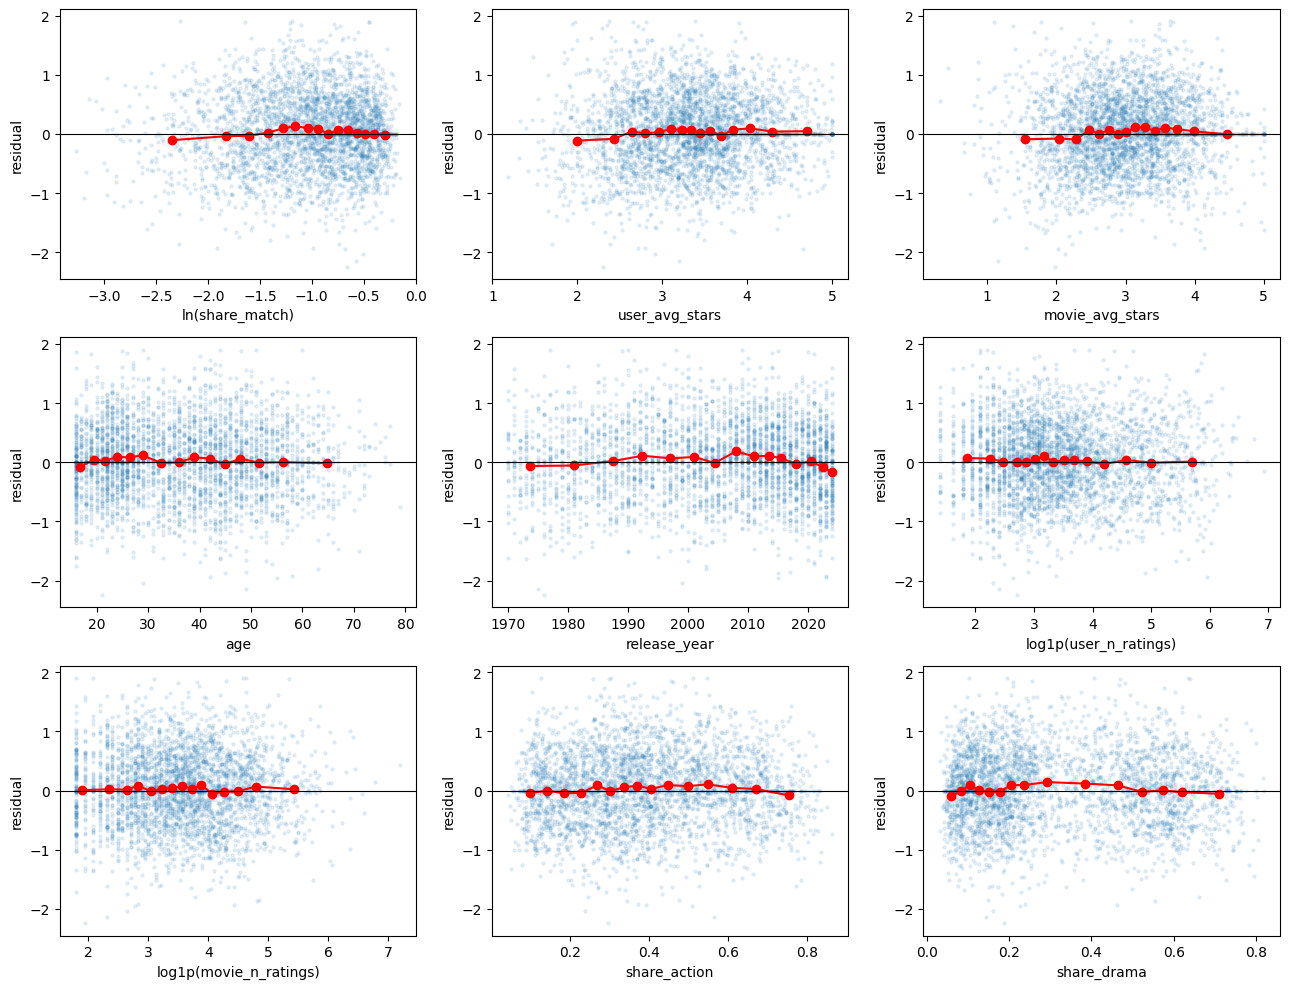

In [ ]:
cands = {
    "ln(share_match)": X3["share_match"],
    "user_avg_stars": X2["user_avg_stars"],
    "movie_avg_stars": X2["movie_avg_stars"],
    "age": X2["age"],
    "release_year": X2["release_year"],
    "log1p(user_n_ratings)": np.log1p(X2["user_n_ratings"]),
    "log1p(movie_n_ratings)": np.log1p(X2["movie_n_ratings"]),
    "share_action": X2["share_action"],
    "share_drama": df["share_drama"],
}

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, (name, xf) in zip(axes.ravel(), cands.items()):
    b = pd.qcut(xf, 15, duplicates="drop")
    m = pd.DataFrame({"x": xf, "r": resid}).groupby(b, observed=True).mean()
    ax.scatter(xf, resid, alpha=0.1, s=5)
    ax.plot(m["x"], m["r"], "r-o")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel(name); ax.set_ylabel("residual")
plt.tight_layout(); plt.show()

Vemos que todas as variáveis e algumas de suas modificações não puxam o resíduo para algum lado. Para melhorar, devemos considerar outros modelos ou criar novas variáveis a partir das que temos.

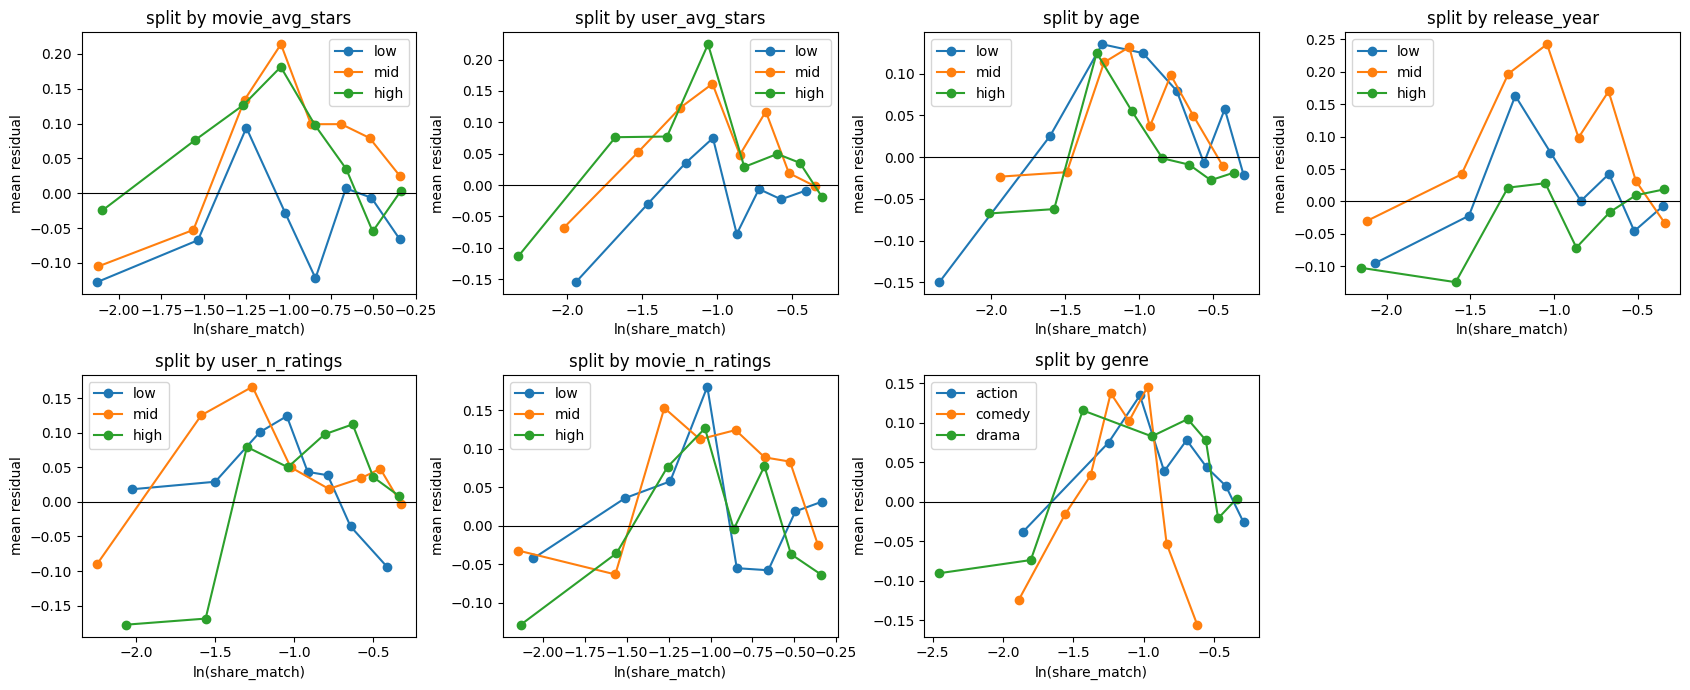

In [ ]:
model = make_pipeline(StandardScaler(), LinearRegression())
pred, resid = oof_residuals(model, X3, y)
resid = np.asarray(resid)

cands = {
    "movie_avg_stars": X3["movie_avg_stars"],
    "user_avg_stars": X3["user_avg_stars"],
    "age": X3["age"],
    "release_year": X3["release_year"],
    "user_n_ratings": X3["user_n_ratings"],
    "movie_n_ratings": X3["movie_n_ratings"],
    "genre": df["genre"],
}

xs = X3["share_match"].to_numpy()               # ln(share_match)
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (name, g) in zip(axes.ravel(), cands.items()):
    if name == "genre":
        labels = sorted(g.unique())
    else:
        g = pd.qcut(g, 3, labels=["low", "mid", "high"])
        labels = ["low", "mid", "high"]
    for lab in labels:
        idx = (g == lab).to_numpy()
        xi, ri = xs[idx], resid[idx]
        b = pd.qcut(xi, 8, duplicates="drop")    # positional, no index involved
        m = pd.DataFrame({"x": xi, "r": ri}).groupby(b, observed=True).mean()
        ax.plot(m["x"], m["r"], "o-", label=lab)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"split by {name}")
    ax.set_xlabel("ln(share_match)"); ax.set_ylabel("mean residual")
    ax.legend()
for ax in axes.ravel()[len(cands):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

De todos os gráficos de perfil, vemos que o mais promissor de conter interação é o de gênero com $\ln{ \text{share\_match} }$.

Outra ideia é levar em conta a idade e o ano de lançamento por meio de uma interação, para tentar capturar a idade do usuário na época.

In [ ]:
X5 = X3.copy()
for g in ["genre_comedy", "genre_drama"]:
    X5[f"sm_x_{g}"] = X5["share_match"] * X5[g]
results["Linear com Interação genre x ln(share_match) e Seleção"] = evaluate(selected_linear(), X5, y)

In [ ]:
X6 = X3.copy()
X6["age_x_year"] = X6["age"] * X6["release_year"]
X6["age_at_release"] = X6["age"] - (2026 - X6["release_year"])

results["Linear com interação age x release_year, Seleção, ln(share_match) e age_at_release"] = evaluate(selected_linear(), X6, y)

In [18]:
pd.set_option("display.max_colwidth", None)
pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear,0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear Aditivo com Seleção,0.8303,0.003,"user_avg_stars, movie_avg_stars, genre_comedy"
Linear Aditivo com Seleção e share_match,0.6547,0.0023,"user_avg_stars, share_comedy, movie_avg_stars, share_match"
Linear Aditivo com Seleção e ln(share_match),0.6187,0.0026,"user_avg_stars, age, share_comedy, movie_avg_stars, release_year, genre_drama, share_match"
Linear Aditivo com Seleção e sqrt(share_match),0.6356,0.0027,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match"
Linear com Interação genre x ln(share_match) e Seleção,0.6218,0.0027,"user_avg_stars, age, movie_avg_stars, release_year, share_match, sm_x_genre_drama"
"Linear com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.6005,0.0043,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match, age_x_year, age_at_release"


Chegamos em ponto de aparente saturação dos modelos lineares. 

# Árvores de Decisão

\{'categorical_features': 'from_dtype',
 'early_stopping': 'auto',
  'interaction_cst': None,
   'l2_regularization': 0.0,
    'learning_rate': 0.05,
     'loss': 'squared_error',
      'max_bins': 255,
       'max_depth': 3,
        'max_features': 1.0,
         'max_iter': 300,
          'max_leaf_nodes': 31,
           'min_samples_leaf': 20,
            'monotonic_cst': None,
             'n_iter_no_change': 10,
             'quantile': None,
              'random_state': None,
               'scoring': 'loss',
                'tol': 1e-07,
                 'validation_fraction': 0.1,
                  'verbose': 0,
                   'warm_start': False\}

In [ ]:
hgb = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300)

results["HistGradientBoostingRegressor com interação age x release_year, Seleção, ln(share_match) e age_at_release"] = evaluate(HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300), X6, y)

\{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.8, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 500, 'n_jobs': -1, 'oob_score': False, 'random_state': 2026, 'verbose': 0, 'warm_start': False\}

In [ ]:
rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=5,   
    max_features=0.80,
    n_jobs=-1,
    random_state=SEED)

results["Random Forest com interação age x release_year, Seleção, ln(share_match) e age_at_release"] = evaluate(rf, X6, y)


In [ ]:
pd.set_option("display.max_colwidth", None)
pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear,0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear Aditivo com Seleção,0.8303,0.003,"user_avg_stars, movie_avg_stars, genre_comedy"
Linear Aditivo com Seleção e share_match,0.6547,0.0023,"user_avg_stars, share_comedy, movie_avg_stars, share_match"
Linear Aditivo com Seleção e ln(share_match),0.6187,0.0026,"user_avg_stars, age, share_comedy, movie_avg_stars, release_year, genre_drama, share_match"
Linear Aditivo com Seleção e sqrt(share_match),0.6356,0.0027,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match"
Linear com Interação genre x ln(share_match) e Seleção,0.6218,0.0027,"user_avg_stars, age, movie_avg_stars, release_year, share_match, sm_x_genre_drama"
"Linear com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.6005,0.0043,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match, age_x_year, age_at_release"
"HistGradientBoostingRegressor com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5119,0.0036,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"
"Random Forest com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5669,0.0026,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"


In [ ]:
# KNN: k
results["KNN (k=10)"] = evaluate(
    make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10, weights="distance")), X6, y)

best_mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        solver="adam",
        hidden_layer_sizes=(128, 64),
        activation="tanh",
        alpha=0.25956879983111314,
        batch_size=128,
        learning_rate="constant",
        learning_rate_init=0.0002674064237843672,
        momentum=0.8,
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=40,
        tol=1e-4,
        random_state=SEED
    )
)

results["Best MLP (128, 64) alpha=0.26"] = evaluate(
    best_mlp, X6, y)

pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear,0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear Aditivo com Seleção,0.8303,0.003,"user_avg_stars, movie_avg_stars, genre_comedy"
Linear Aditivo com Seleção e share_match,0.6547,0.0023,"user_avg_stars, share_comedy, movie_avg_stars, share_match"
Linear Aditivo com Seleção e ln(share_match),0.6187,0.0026,"user_avg_stars, age, share_comedy, movie_avg_stars, release_year, genre_drama, share_match"
Linear Aditivo com Seleção e sqrt(share_match),0.6356,0.0027,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match"
Linear com Interação genre x ln(share_match) e Seleção,0.6218,0.0027,"user_avg_stars, age, movie_avg_stars, release_year, share_match, sm_x_genre_drama"
"Linear com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.6005,0.0043,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match, age_x_year, age_at_release"
"HistGradientBoostingRegressor com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5119,0.0036,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"
"Random Forest com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5669,0.0026,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"


In [ ]:
param_dist_lgbm = {
    "learning_rate":     loguniform(0.01, 0.08),
    "n_estimators":      randint(200, 800),
    "num_leaves":        randint(4, 16),
    "min_child_samples": randint(15, 60),
    "subsample":         uniform(0.6, 0.4),         # 0.6 to 1.0
    "colsample_bytree":  uniform(0.6, 0.4),
    "reg_lambda":        loguniform(1e-2, 10),
}

def tuned_lgbm():
    return RandomizedSearchCV(
        LGBMRegressor(subsample_freq=1, random_state=SEED, n_jobs=1, verbose=-1),
        param_distributions=param_dist_lgbm,
        n_iter=30, cv=5,
        scoring="neg_root_mean_squared_error",
        random_state=SEED, n_jobs=-1)

search = tuned_lgbm().fit(X6, y)


# 1. Fixed model with the tuned parameters (optimistic row: parameters chosen on the same rows)
best_params = {k: (int(v) if isinstance(v, (int, np.integer)) else float(v))
               for k, v in search.best_params_.items()}

best_lgbm = LGBMRegressor(**best_params, subsample_freq=1,
                          random_state=SEED, n_jobs=-1, verbose=-1)

results["LightGBM (best params, optimistic)"] = evaluate(best_lgbm, X6, y)

# 2. Honest row: the whole search repeated inside each outer fold (slow)
results["LightGBM tunado (nested CV)"] = evaluate(tuned_lgbm(), X6, y)

pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear,0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear Aditivo com Seleção,0.8303,0.003,"user_avg_stars, movie_avg_stars, genre_comedy"
Linear Aditivo com Seleção e share_match,0.6547,0.0023,"user_avg_stars, share_comedy, movie_avg_stars, share_match"
Linear Aditivo com Seleção e ln(share_match),0.6187,0.0026,"user_avg_stars, age, share_comedy, movie_avg_stars, release_year, genre_drama, share_match"
Linear Aditivo com Seleção e sqrt(share_match),0.6356,0.0027,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match"
Linear com Interação genre x ln(share_match) e Seleção,0.6218,0.0027,"user_avg_stars, age, movie_avg_stars, release_year, share_match, sm_x_genre_drama"
"Linear com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.6005,0.0043,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match, age_x_year, age_at_release"
"HistGradientBoostingRegressor com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5119,0.0036,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"
"Random Forest com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5669,0.0026,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"


In [ ]:
xgb_best = XGBRegressor(
    n_estimators=400, learning_rate=0.05, max_depth=3,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=1.0, tree_method="hist",
    random_state=SEED, n_jobs=-1)

results["XGBoost (depth 3, lr 0.05, 400 it)"] = evaluate(xgb_best, X6, y)
pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear,0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear Aditivo com Seleção,0.8303,0.003,"user_avg_stars, movie_avg_stars, genre_comedy"
Linear Aditivo com Seleção e share_match,0.6547,0.0023,"user_avg_stars, share_comedy, movie_avg_stars, share_match"
Linear Aditivo com Seleção e ln(share_match),0.6187,0.0026,"user_avg_stars, age, share_comedy, movie_avg_stars, release_year, genre_drama, share_match"
Linear Aditivo com Seleção e sqrt(share_match),0.6356,0.0027,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match"
Linear com Interação genre x ln(share_match) e Seleção,0.6218,0.0027,"user_avg_stars, age, movie_avg_stars, release_year, share_match, sm_x_genre_drama"
"Linear com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.6005,0.0043,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match, age_x_year, age_at_release"
"HistGradientBoostingRegressor com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5119,0.0036,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"
"Random Forest com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5669,0.0026,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"


In [ ]:
results["SVR (rbf, C=1, eps=0.1)"] = evaluate(
    make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1, epsilon=0.1, gamma="scale")), X6, y)

pd.DataFrame(results, index=["CV RMSE", "SE", "Variables"]).T

,CV RMSE,SE,Variables
Constante,1.1678,0.0016,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear,0.827,0.0028,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama"
Linear Aditivo com Seleção,0.8303,0.003,"user_avg_stars, movie_avg_stars, genre_comedy"
Linear Aditivo com Seleção e share_match,0.6547,0.0023,"user_avg_stars, share_comedy, movie_avg_stars, share_match"
Linear Aditivo com Seleção e ln(share_match),0.6187,0.0026,"user_avg_stars, age, share_comedy, movie_avg_stars, release_year, genre_drama, share_match"
Linear Aditivo com Seleção e sqrt(share_match),0.6356,0.0027,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match"
Linear com Interação genre x ln(share_match) e Seleção,0.6218,0.0027,"user_avg_stars, age, movie_avg_stars, release_year, share_match, sm_x_genre_drama"
"Linear com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.6005,0.0043,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match, age_x_year, age_at_release"
"HistGradientBoostingRegressor com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5119,0.0036,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"
"Random Forest com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5669,0.0026,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release"


# README e Requirements

In [ ]:
# Requirements

from importlib.metadata import version

packages = ["numpy", "pandas", "matplotlib", "scipy", "scikit-learn", "lightgbm", "xgboost"]

with open("requirements.txt", "w") as f:
    for p in packages:
        f.write(f"{p}=={version(p)}\n")

print(open("requirements.txt").read())

numpy==2.1.3
pandas==2.3.3
matplotlib==3.10.9
scipy==1.17.1
scikit-learn==1.9.0
lightgbm==4.7.0
xgboost==3.4.1



In [ ]:
# Hold-out evaluation for every model in `results`
holdout_df = hold_out.copy()

X_holdout = pd.get_dummies(
    holdout_df.drop(columns=["pair_id", "stars"]),
    columns=["genre"],
    drop_first=True
)
X_holdout = X_holdout.drop(columns=["share_drama"], errors="ignore")
X_holdout = X_holdout.reindex(columns=X.columns, fill_value=0)

# Recreate the feature engineering used by the candidate models.
raw_match_train = df.apply(lambda r: r[f"share_{r['genre']}"], axis=1)
raw_match_holdout = holdout_df.apply(lambda r: r[f"share_{r['genre']}"], axis=1)

X2_holdout = X_holdout.copy()
X2_holdout["share_match"] = raw_match_holdout

X3_holdout = X2_holdout.copy()
X3_holdout["share_match"] = np.log(X3_holdout["share_match"])

X4_holdout = X2_holdout.copy()
X4_holdout["share_match"] = np.sqrt(X4_holdout["share_match"])

X5_holdout = X3_holdout.copy()
for g in ["genre_comedy", "genre_drama"]:
    X5_holdout[f"sm_x_{g}"] = X5_holdout["share_match"] * X5_holdout[g]

X6_holdout = X3_holdout.copy()
X6_holdout["age_x_year"] = X6_holdout["age"] * X6_holdout["release_year"]
X6_holdout["age_at_release"] = X6_holdout["age"] - (2026 - X6_holdout["release_year"])

y_holdout = holdout_df["stars"]

holdout_rmse = []
for model, X_train_model in evaluation_specs:
    # Select the matching hold-out transformation for the share_match feature.
    if "share_match" not in X_train_model.columns:
        X_test_all = X_holdout
    elif np.allclose(X_train_model["share_match"], raw_match_train):
        X_test_all = X2_holdout
    elif np.allclose(X_train_model["share_match"], np.log(raw_match_train)):
        X_test_all = X3_holdout
    elif np.allclose(X_train_model["share_match"], np.sqrt(raw_match_train)):
        X_test_all = X4_holdout
    else:
        raise ValueError("Could not identify the share_match transformation.")

    # Models with engineered interactions need their corresponding hold-out columns.
    if "sm_x_genre_comedy" in X_train_model.columns or "sm_x_genre_drama" in X_train_model.columns:
        X_test_all = X5_holdout
    if "age_x_year" in X_train_model.columns or "age_at_release" in X_train_model.columns:
        X_test_all = X6_holdout

    X_train_model = X_train_model.copy()
    X_test_model = X_test_all.reindex(columns=X_train_model.columns, fill_value=0)

    fitted_model = clone(model).fit(X_train_model, y)
    predictions = np.clip(fitted_model.predict(X_test_model), 0, 5)
    holdout_rmse.append(np.sqrt(mean_squared_error(y_holdout, predictions)))

if len(holdout_rmse) != len(results):
    raise ValueError(
        f"Mismatch: {len(results)} result rows but {len(holdout_rmse)} hold-out scores."
    )

results_df = pd.DataFrame(
    results, index=["CV RMSE", "SE", "Variables"]
).T

results_df["CV RMSE"] = pd.to_numeric(results_df["CV RMSE"])
results_df["SE"] = pd.to_numeric(results_df["SE"])
results_df["Hold-out RMSE"] = np.round(holdout_rmse, 4)
results_df["Difference (Hold-out - CV)"] = (
    results_df["Hold-out RMSE"] - results_df["CV RMSE"]
).round(4)

results_df.sort_values("CV RMSE")


,CV RMSE,SE,Variables,Hold-out RMSE,Difference (Hold-out - CV)
"Best MLP (128, 64) alpha=0.26",0.4929,0.0032,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release",0.4946,0.0017
"XGBoost (depth 3, lr 0.05, 400 it)",0.5039,0.0033,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release",0.5077,0.0038
"LightGBM (best params, optimistic)",0.5065,0.0031,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release",0.5081,0.0016
LightGBM tunado (nested CV),0.5080,0.0033,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release",0.5081,0.0001
"HistGradientBoostingRegressor com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5119,0.0036,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release",0.5157,0.0038
"SVR (rbf, C=1, eps=0.1)",0.5376,0.0042,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release",0.5451,0.0075
"Random Forest com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.5669,0.0026,"user_avg_stars, user_n_ratings, age, share_action, share_comedy, movie_avg_stars, movie_n_ratings, release_year, genre_comedy, genre_drama, share_match, age_x_year, age_at_release",0.5591,-0.0078
"Linear com interação age x release_year, Seleção, ln(share_match) e age_at_release",0.6005,0.0043,"user_avg_stars, age, share_comedy, movie_avg_stars, genre_drama, share_match, age_x_year, age_at_release",0.5898,-0.0107
Linear Aditivo com Seleção e ln(share_match),0.6187,0.0026,"user_avg_stars, age, share_comedy, movie_avg_stars, release_year, genre_drama, share_match",0.6132,-0.0055
Linear com Interação genre x ln(share_match) e Seleção,0.6218,0.0027,"user_avg_stars, age, movie_avg_stars, release_year, share_match, sm_x_genre_drama",0.6170,-0.0048


In [ ]:
def write_readme(results_df, path="README.md",
                 title="Projeto MAE0501: Prevendo avaliações de filmes"):

    rows = results_df.sort_values("CV RMSE").iterrows()

    table = [
        "| Model | CV RMSE | SE | Variables | Hold-out RMSE | Difference |",
        "|---|---:|---:|---|---:|---:|"
    ]

    for name, row in rows:
        table.append(
            f"| {name} "
            f"| {row['CV RMSE']:.4f} "
            f"| {row['SE']:.4f} "
            f"| {row['Variables']} "
            f"| {row['Hold-out RMSE']:.4f} "
            f"| {row['Difference (Hold-out - CV)']:.4f} |"
        )

    text = f"""# {title}

## Requirements

```bash
python -m pip install -r requirements.txt
```

## Resultados

RMSE por Validação Cruzada 5-fold 3 vezes em `pure_train`;

{chr(10).join(table)}
"""
    Path(path).write_text(text, encoding="utf-8")
    print(f"{path} written ({len(results_df)} models)")

write_readme(results_df)

README.md written (16 models)
